# Aspects mentioned in game reviews

Games are ordered by numeric Steam app ID. Match whole words and adjacent bigrams within sentences, ignoring case, using `src.aspects.ASPECTS`. Count each aspect once per review, even if mentioned repeatedly; a review can match multiple aspects. Duplicate review IDs and blank reviews are excluded.

The table shows **count (% of that game's reviews)**. The overall summary weights reviews equally across the selected games. These are vocabulary mentions, not sentiment or confirmed relevance. Run from the project root or `notebooks/`; clustering requires numpy and scikit-learn. No cache changes.

The mechanics vocabulary is a starting hypothesis. Keywords can be ambiguous (for example, “farming” enemies or “building” a character), and mentions do not establish that a mechanic is present. Categories can overlap. Change `ASPECTS` to compare vocabularies.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

from src.aspects import ASPECTS
from src.csv_io import REVIEWS_DATA_DIR, load_reviews
from src.review_parser import ReviewParser

N_GAMES = 10000
parser = ReviewParser()
aspects = {name: set(words) for name, words in ASPECTS.items()}
files = sorted((p for p in REVIEWS_DATA_DIR.glob("*.csv") if p.stem.isdigit()),
               key=lambda p: int(p.stem))[:N_GAMES]


In [2]:
summary = []
for path in files:
    reviews = {r.recommendationid: r for r in load_reviews(int(path.stem))
               if r.review.strip()}
    counts = dict.fromkeys(aspects, 0)
    for review in reviews.values():
        words = set()
        for tokens in parser.tokenize(parser.split_to_sentences(review.review)):
            words.update(tokens)
            words.update(a + " " + b for a, b in zip(tokens, tokens[1:]))
        for aspect, vocabulary in aspects.items():
            counts[aspect] += bool(words & vocabulary)
    summary.append({"appid": int(path.stem), "reviews": len(reviews), **counts})

n_reviews = sum(row["reviews"] for row in summary)
print(f"{len(summary)} games, {n_reviews:,} unique nonblank reviews")
for aspect in aspects:
    count = sum(row[aspect] for row in summary)
    print(f"{aspect:12} {count:6,} reviews ({count / max(n_reviews, 1):.1%})")


969 games, 92,488 unique nonblank reviews
combat       16,882 reviews (18.3%)
shooting      7,982 reviews (8.6%)
stealth       2,779 reviews (3.0%)
platforming   3,199 reviews (3.5%)
survival      5,357 reviews (5.8%)
crafting      2,832 reviews (3.1%)
sports        1,877 reviews (2.0%)
strategy      7,037 reviews (7.6%)
building      8,638 reviews (9.3%)
horror        5,302 reviews (5.7%)
story        33,228 reviews (35.9%)
graphics     22,027 reviews (23.8%)
audio        17,827 reviews (19.3%)
performance  17,961 reviews (19.4%)
multiplayer  19,989 reviews (21.6%)
modding       6,357 reviews (6.9%)


## Cluster games by aspect percentages

Standardize the aspect percentages so each aspect has equal influence, then apply K-means. No dimensionality reduction is needed. Change `N_CLUSTERS` to explore different groupings.

Profiles average percentages equally across games; “above average” compares with all included games in percentage points. Games without nonblank reviews are excluded. These clusters describe review discussion patterns, not sentiment or quality. Games with few reviews have less stable estimates.

App IDs within each cluster are ordered by Euclidean distance to the cluster mean in standardized aspect space, closest first.

In [3]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

N_CLUSTERS = 10
games = [row for row in summary if row["reviews"]]
names = np.array(list(aspects))
shares = np.array([[row[a] / row["reviews"] for a in aspects] for row in games])
scaled = StandardScaler().fit_transform(shares)
labels = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=42).fit_predict(
    scaled
)
for row, label in zip(games, labels):
    row["cluster"] = int(label)

for cluster in sorted(set(labels)):
    members = np.flatnonzero(labels == cluster)
    distances = np.linalg.norm(scaled[members] - scaled[members].mean(axis=0), axis=1)
    members = members[np.argsort(distances, kind="stable")]
    profile = shares[members].mean(axis=0)
    difference = profile - shares.mean(axis=0)
    top = np.flatnonzero(difference > 0)
    top = top[np.argsort(difference[top])[::-1]][:3]
    print(f"\nCluster {cluster}: {len(members)} games")
    print("Mean shares:", ", ".join(f"{a} {p:.0%}" for a, p in zip(names, profile)))
    print("Above average:", ", ".join(f"{names[i]} +{difference[i]*100:.1f} pp" for i in top) or "none")
    print("App IDs (closest to center first):", ", ".join(str(games[i]["appid"]) for i in members))



Cluster 0: 35 games
Mean shares: combat 19%, shooting 6%, stealth 3%, platforming 35%, survival 5%, crafting 2%, sports 1%, strategy 3%, building 5%, horror 7%, story 49%, graphics 42%, audio 38%, performance 17%, multiplayer 13%, modding 3%
Above average: platforming +31.5 pp, audio +19.5 pp, graphics +18.9 pp
App IDs (closest to center first): 299460, 1139900, 48000, 26800, 224760, 17410, 2231450, 275390, 35720, 40800, 238460, 96100, 774361, 268910, 304430, 35700, 203160, 33230, 8190, 504230, 996580, 1057090, 261570, 225540, 387290, 303390, 683320, 585690, 278360, 782330, 289650, 424840, 368500, 534380, 239140

Cluster 1: 178 games
Mean shares: combat 30%, shooting 7%, stealth 2%, platforming 4%, survival 5%, crafting 3%, sports 1%, strategy 5%, building 6%, horror 3%, story 59%, graphics 34%, audio 30%, performance 20%, multiplayer 13%, modding 4%
Above average: story +24.7 pp, combat +12.5 pp, audio +11.7 pp
App IDs (closest to center first): 920210, 1245620, 851850, 460790, 23220

## Silhouette plot

Run after the clustering cell. Each horizontal bar is one game, grouped by cluster and sorted by its silhouette score. Wider bands contain more games. Scores near 1 indicate good separation, near 0 indicate overlap, and negative scores suggest a game is closer on average to another cluster. The dashed line is the overall mean. Change `N_CLUSTERS`, rerun clustering, then rerun this plot to compare. Requires matplotlib.

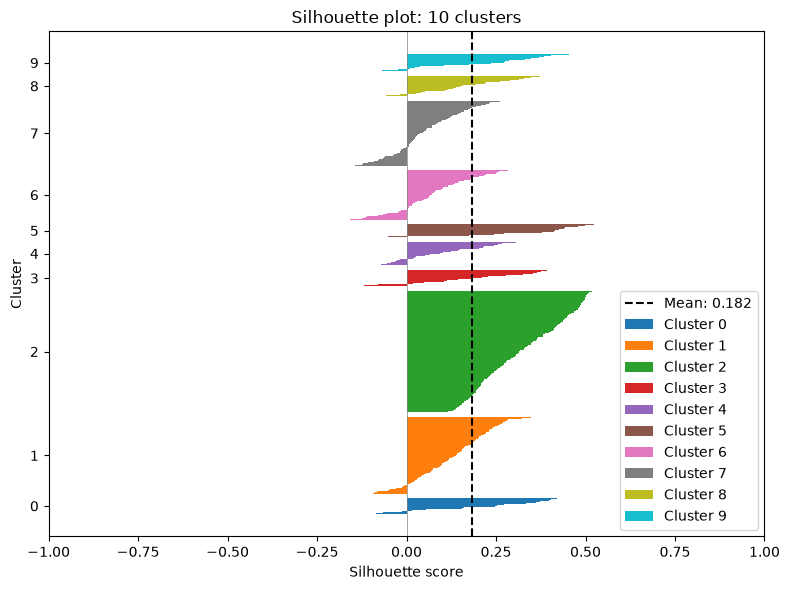

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_samples

scores = silhouette_samples(scaled, labels)
fig, ax = plt.subplots(figsize=(8, 6))
start, ticks = 0, []
for cluster in sorted(set(labels)):
    values = np.sort(scores[labels == cluster])
    positions = np.arange(start, start + len(values))
    ax.barh(positions, values, height=1, label=f"Cluster {cluster}")
    ticks.append(positions.mean())
    start += len(values) + 10
ax.axvline(scores.mean(), color="black", linestyle="--", label=f"Mean: {scores.mean():.3f}")
ax.axvline(0, color="grey", linewidth=0.5)
ax.set(xlabel="Silhouette score", ylabel="Cluster", xlim=(-1, 1),
       yticks=ticks, yticklabels=sorted(set(labels)),
       title=f"Silhouette plot: {len(set(labels))} clusters")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()
